# WSFF — Weighted skip-connection feature fusion for UAV rice panicle segmentation (minimal reproduction)

**Paper:** Luolin Xiao, Zhibin Pan, Xiaoyong Du, Wei Chen, Wenpeng Qu, Youda Bai, Tian Xu.
*Weighted skip-connection feature fusion: A method for augmenting UAV oriented rice panicle image segmentation.*
**Computers and Electronics in Agriculture 207 (2023) 107754**. [DOI: 10.1016/j.compag.2023.107754](https://doi.org/10.1016/j.compag.2023.107754)

**Author code & data:** [`rooooolin/wsff`](https://github.com/rooooolin/wsff) @ commit `0d3bc2487bf01339ee231dbd15368762d6b612d6`
(`models.py` git blob `9335d752e1e0b58e18105c6d594519db284f12c0` — verified after download below).

**Scope of this notebook (one minimal experience):** train the paper's **WSUNet** on a
400-tile subset of the embedded **FSF1E** 256×256 RGB tiles and evaluate it on the
repository's 328-tile validation split (IoU / Dice / pixel-F1), then visualize an
input tile against its reference annotation and the model prediction.

**Execution status:** this notebook is *executed and validated on a Colab T4 GPU*.
It requires a GPU runtime (see below) and fails fast on CPU.

> **⚠️ AI-assisted training protocol — please read.**
> The authors released **model definitions and the dataset only**; the repository
> contains **no training/evaluation scripts, no hyperparameters, no configuration
> file, and no pretrained weights**, and the article full text was not accessible
> (paywalled; no open-access copy located; OpenAlex has no cached copy). The
> training loop, loss, optimizer, learning rate, subset sizes and metric
> definitions below are **AI-authored defaults written for this demonstration** —
> they are *not* the authors' protocol, and the numbers produced here do **not**
> reproduce the paper's reported benchmark metrics.
>
> **（日本語）** 著者はモデル定義とデータセットのみを公開しており、学習・評価コードや
> ハイパーパラメータ、事前学習重みはありません（論文本文も入手不可）。以下の学習ループや
> ハイパーパラメータはこのデモンストレーション用に AI が作成したものであり、著者の
> プロトコルではありません。ここで得られる数値は論文のベンチマーク結果の再現ではありません。

**Runtime:** Colab **T4 GPU**. Expected wall time ≈ 10–15 min total; download ≈ 75 MB
(sparse clone of `data/FSF1E` + `models.py` at the pinned commit).
**（日本語）** ランタイムは T4 GPU を選択してください。全体で約 10〜15 分、ダウンロード約 75 MB です。

## 1. Environment check

We verify the Python/PyTorch versions and the CUDA GPU. This notebook trains a
5-level U-Net-family model (32→512 channels) on 256×256 tiles; on CPU a useful
training budget would take far too long, so the notebook **fails fast** if no GPU
is visible. Select `Runtime → Change runtime type → T4 GPU` before running.

**（日本語）** Python/PyTorch のバージョンと CUDA GPU を確認します。CPU では学習が現実的な
時間で終わらないため、GPU が無い場合はここで明示的に停止します。
`ランタイム → ランタイムのタイプを変更 → T4 GPU` を選択してから実行してください。

In [ ]:
import sys, torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. This minimal WSUNet *training* demo requires a "
        "Colab T4 GPU runtime: Runtime > Change runtime type > T4 GPU. "
        "(CPU training of this model is impractically slow for a hands-on demo.)"
    )
DEVICE = torch.device("cuda:0")
print("Device:", torch.cuda.get_device_name(0))
torch.manual_seed(0)

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
Device: Tesla T4


## 2. Pin and download the author repository (code + embedded FSF1E tiles)

The author's repository embeds the tiled dataset itself, so a single pinned Git
fetch provides both `models.py` and the FSF1E images/masks. We use a
**blob-filtered, no-checkout clone with a cone sparse-checkout** limited to
`data/FSF1E` (≈73 MB) plus the root code files, then fetch and check out the
**exact commit** `0d3bc2487bf0…` in detached HEAD. All repository bytes stay
under `/content` on this Colab VM. A shallow clone of the default branch alone
would not pin the 2023-08-15 commit, so we fetch the commit object explicitly and
**assert** the checked-out SHA matches.

**（日本語）** 著者リポジトリはデータタイルを含むため、blob フィルタ + sparse-checkout で
`data/FSF1E` とコードのみを取得し、**指定コミットに detached HEAD でチェックアウト**して
SHA を検証します。取得バイトはすべて Colab VM 上の `/content` に置かれます。

In [ ]:
import subprocess, os

REPO = "/content/wsff"
COMMIT = "0d3bc2487bf01339ee231dbd15368762d6b612d6"

def sh(cmd):
    print("+", " ".join(cmd), flush=True)
    subprocess.run(cmd, check=True, cwd=os.path.dirname(REPO) if os.path.isdir(REPO) else ".")

if not os.path.isdir(REPO):
    sh(["git", "clone", "--filter=blob:none", "--no-checkout",
        "https://github.com/rooooolin/wsff", REPO])
sh(["git", "-C", REPO, "sparse-checkout", "init", "--cone"])
sh(["git", "-C", REPO, "sparse-checkout", "set", "data/FSF1E"])
sh(["git", "-C", REPO, "fetch", "--depth", "1", "origin", COMMIT])
sh(["git", "-C", REPO, "checkout", "--detach", "FETCH_HEAD"])

head = subprocess.run(["git", "-C", REPO, "rev-parse", "HEAD"],
                      check=True, capture_output=True, text=True).stdout.strip()
assert head == COMMIT, f"checkout {head} != pinned {COMMIT}"
print("Checked out pinned commit:", head)

+ git clone --filter=blob:none --no-checkout https://github.com/rooooolin/wsff /content/wsff


+ git -C /content/wsff sparse-checkout init --cone


+ git -C /content/wsff sparse-checkout set data/FSF1E


+ git -C /content/wsff fetch --depth 1 origin 0d3bc2487bf01339ee231dbd15368762d6b612d6


+ git -C /content/wsff checkout --detach FETCH_HEAD


Checked out pinned commit: 0d3bc2487bf01339ee231dbd15368762d6b612d6


## 3. Verify the downloaded tree and import the author's model

Before any science: confirm the expected **1418 train / 328 validation** image and
mask tiles exist, and that `models.py` matches the pinned git blob SHA
(`git hash-object` recomputes it from the downloaded bytes). Then import the
author's `WSUNet` class directly from the checked-out repository — the model code
is used exactly as published (only imported, never modified).

**（日本語）** 1418/328 枚のタイル数と `models.py` の git blob SHA を検証し、著者の
`WSUNet` をそのままインポートして使用します（モデルコードは改変しません）。

In [ ]:
import hashlib, pathlib, subprocess

ROOT = pathlib.Path("/content/wsff")
for sub, n in [("images/train", 1418), ("images/val", 328),
               ("masks/train", 1418), ("masks/val", 328)]:
    files = sorted((ROOT / "data/FSF1E" / sub).glob("*"))
    assert len(files) == n, (sub, len(files), n)
    print(f"data/FSF1E/{sub}: {len(files)} files ✓")

blob = subprocess.run(["git", "-C", str(ROOT), "hash-object", "models.py"],
                      check=True, capture_output=True, text=True).stdout.strip()
assert blob == "9335d752e1e0b58e18105c6d594519db284f12c0", blob
print("models.py git blob sha ✓", blob)

sys.path.insert(0, str(ROOT))
import models  # author's file, pinned commit
print("Imported author models:", [n for n in ("UNet", "NestedUNet", "WSUNet", "WS1UNet", "WS2UNet") if hasattr(models, n)])

data/FSF1E/images/train: 1418 files ✓
data/FSF1E/images/val: 328 files ✓


data/FSF1E/masks/train: 1418 files ✓
data/FSF1E/masks/val: 328 files ✓
models.py git blob sha ✓ 9335d752e1e0b58e18105c6d594519db284f12c0
Imported author models: ['UNet', 'NestedUNet', 'WSUNet', 'WS1UNet', 'WS2UNet']


## 4. Inspect tile and mask encoding

The masks are stored as JPEGs with the same filenames as the images. JPEG is
lossy, so a binary annotation is stored as near-0 / near-255 values. We inspect
a few tiles (size, mode, unique value ranges) **before** fixing a threshold, and
define the mask loader to binarize at >127 (0/1 or 0/255 encodings both work).

**（日本語）** マスクは JPEG で保存されているため、0/255 の近似値で格納されているはずです。
実データを検査してから、>127 で二値化するローダを定義します（0/1 と 0/255 の両方に対応）。

In [ ]:
import numpy as np
from PIL import Image

def load_image(p):
    return np.asarray(Image.open(p).convert("RGB"), dtype=np.float32) / 255.0

def load_mask(p):
    m = np.asarray(Image.open(p).convert("L"))
    return (m > 127).astype(np.float32)

for p in [ROOT / "data/FSF1E/images/train/DJI_0044.JPG_00.jpg",
          ROOT / "data/FSF1E/masks/train/DJI_0044.JPG_00.jpg",
          ROOT / "data/FSF1E/masks/val/DJI_0044.JPG_013.jpg"]:
    a = np.asarray(Image.open(p))
    print(p.relative_to(ROOT), a.shape, a.dtype, "min/max:", a.min(), a.max())

m = load_mask(ROOT / "data/FSF1E/masks/train/DJI_0044.JPG_00.jpg")
print("binarized train mask: shape", m.shape, "panicle fraction:", round(float(m.mean()), 4))
img = load_image(ROOT / "data/FSF1E/images/train/DJI_0044.JPG_00.jpg")
print("image tile: shape", img.shape, "RGB in [0,1]")

from torch.utils.data import Dataset

class FSF1ETiles(Dataset):
    """FSF1E 256x256 tiles: RGB image (3,H,W) in [0,1] + binary mask (1,H,W)."""
    def __init__(self, root, split, names):
        self.img_dir = pathlib.Path(root) / "data/FSF1E/images" / split
        self.mask_dir = pathlib.Path(root) / "data/FSF1E/masks" / split
        self.names = names
    def __len__(self):
        return len(self.names)
    def __getitem__(self, i):
        name = self.names[i]
        x = torch.from_numpy(load_image(self.img_dir / name)).permute(2, 0, 1)
        y = torch.from_numpy(load_mask(self.mask_dir / name)).unsqueeze(0)
        return x, y

data/FSF1E/images/train/DJI_0044.JPG_00.jpg (256, 256, 3) uint8 min/max: 0 255
data/FSF1E/masks/train/DJI_0044.JPG_00.jpg (256, 256) uint8 min/max: 0 255
data/FSF1E/masks/val/DJI_0044.JPG_013.jpg (256, 256) uint8 min/max: 0 255
binarized train mask: shape (256, 256) panicle fraction: 0.3292
image tile: shape (256, 256, 3) RGB in [0,1]


## 5. Choose the minimal subset and preview the real data

We take a **seeded random subset of 400 training tiles** (of 1418) — the minimal
experience stays inside a hands-on budget — and keep all **328 validation tiles**
for evaluation. The figure below shows two actual tiles from the downloaded
repository: the original UAV image, the **reference annotation** (mask contour
overlaid on the image), and the binary ground-truth mask. This is the first saved
figure of the notebook (input + real annotation).

**（日本語）** 学習には 400 枚（シード固定で無作為抽出）、評価には全 328 枚の検証タイルを
使用します。下図は実際にダウンロードしたタイル（原画像、アノテーション重ね合わせ、
二値マスク）のプレビューです。

train subset: 400 of 1418 tiles (seed 0)
validation: all 328 tiles


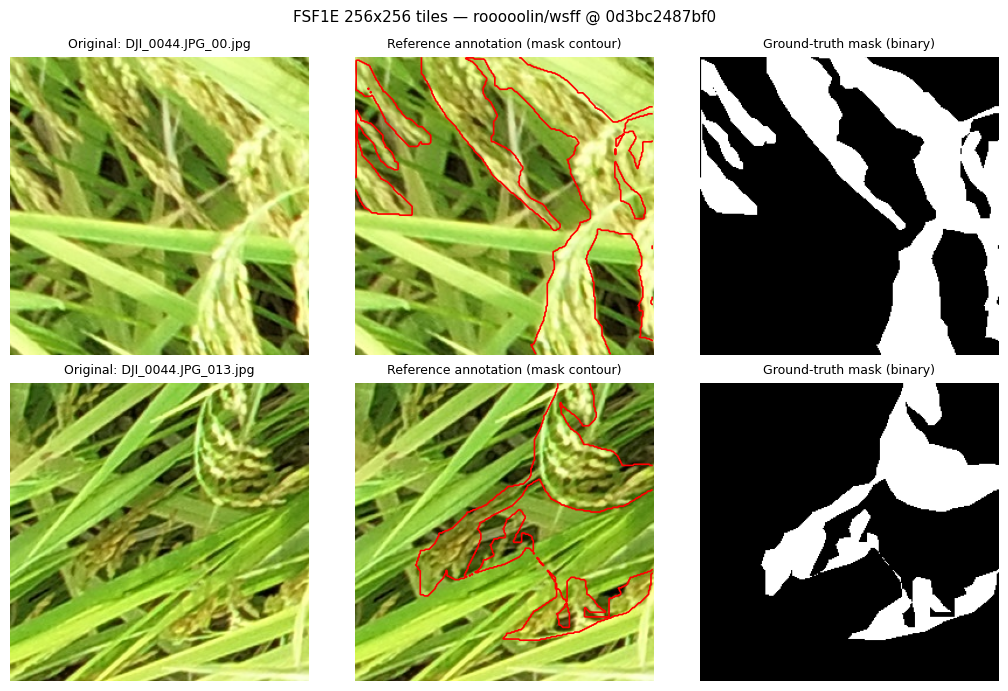

In [ ]:
import random
from torch.utils.data import DataLoader

train_names = sorted(p.name for p in (ROOT / "data/FSF1E/images/train").glob("*"))
val_names = sorted(p.name for p in (ROOT / "data/FSF1E/images/val").glob("*"))
rng = random.Random(0)
SUBSET_N = 400
train_subset = sorted(rng.sample(train_names, SUBSET_N))
print(f"train subset: {len(train_subset)} of {len(train_names)} tiles (seed 0)")
print(f"validation: all {len(val_names)} tiles")

train_ds = FSF1ETiles(ROOT, "train", train_subset)
val_ds = FSF1ETiles(ROOT, "val", val_names)
train_dl = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2,
                      pin_memory=True, drop_last=True)
val_dl = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

import matplotlib.pyplot as plt

def show_tile(ax_img, ax_ov, ax_ms, name):
    img = load_image(ROOT / "data/FSF1E/images/train" / name) if name in train_subset else \
          load_image(ROOT / "data/FSF1E/images/val" / name)
    msk = load_mask((ROOT / "data/FSF1E/masks/train" / name).exists()
                    and ROOT / "data/FSF1E/masks/train" / name
                    or ROOT / "data/FSF1E/masks/val" / name)
    ax_img.imshow(img); ax_img.set_title(f"Original: {name}", fontsize=9)
    ax_img.axis("off")
    ax_ov.imshow(img); ax_ov.contour(msk, levels=[0.5], colors="red", linewidths=1.2)
    ax_ov.set_title("Reference annotation (mask contour)", fontsize=9)
    ax_ov.axis("off")
    ax_ms.imshow(msk, cmap="gray"); ax_ms.set_title("Ground-truth mask (binary)", fontsize=9)
    ax_ms.axis("off")

fig, axes = plt.subplots(2, 3, figsize=(10.5, 7))
show_tile(*axes[0], "DJI_0044.JPG_00.jpg")   # train subset sample
show_tile(*axes[1], val_names[0])            # validation sample
fig.suptitle("FSF1E 256x256 tiles — rooooolin/wsff @ " + COMMIT[:12], fontsize=11)
fig.tight_layout()
plt.savefig("/content/fsf1e_preview.png", dpi=110, bbox_inches="tight")
plt.show()

## 6. Instantiate WSUNet and state the (AI-chosen) training configuration

`WSUNet` is the paper's proposed architecture: a U-Net in which encoder features
are fused across scales by **learnable scalar weights** (`ew*`, initialized 1/2,
1/3, 1/4 by number of contributing paths) through the author's `Down`
(AvgPool + 1×1 conv) shortcuts, and decoder features are fused by `dw*` scalars
through `Up` (PixelShuffle + 1×1 conv) — see `models.py` lines ~176–258 at the
pinned commit. We print the parameter count and the initial fusion weights.

**Configuration (AI-authored — not the authors' protocol):** binary segmentation
with a single logit output, `BCEWithLogitsLoss`, Adam (lr 1e-3), batch 8,
8 epochs ⇒ 400 iterations on the 400-tile subset. These are simple, documented
defaults because the paper's training protocol is unavailable.

**（日本語）** WSUNet は、エンコーダ/デコーダのスキップ経路を学習可能なスカラー重みで
融合するのが提案手法の核です。損失・最適化・エポック数などは著者のプロトコルが不明のため
AI が選んだ既定値であることを明記しています。

In [ ]:
model = models.WSUNet(num_classes=1, input_channels=3).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"WSUNet parameters: {n_params:,}")

fusion = {n: float(p.detach()) for n, p in model.named_parameters()
          if n.startswith(("ew", "dw"))}
print("Initial learnable fusion weights (author defaults):")
for k in sorted(fusion):
    print(f"  {k:8s} = {fusion[k]:.3f}")

loss_fn = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 8
print(f"Training config: BCEWithLogitsLoss, Adam(lr=1e-3), batch=8, epochs={EPOCHS}, "
      f"iterations={EPOCHS * len(train_dl)}")

WSUNet parameters: 7,934,643
Initial learnable fusion weights (author defaults):
  dw0      = 0.250
  dw1      = 0.330
  dw2      = 0.500
  dw2_0    = 0.250
  dw3_0    = 0.250
  dw3_1    = 0.330
  dw4_0    = 0.250
  dw4_1    = 0.330
  dw4_2    = 0.500
  ew0_2    = 0.500
  ew0_3    = 0.330
  ew0_4    = 0.250
  ew1_3    = 0.330
  ew1_4    = 0.250
  ew2      = 0.500
  ew2_4    = 0.250
  ew3      = 0.330
  ew4      = 0.250


Training config: BCEWithLogitsLoss, Adam(lr=1e-3), batch=8, epochs=8, iterations=400


## 7. Train WSUNet on the 400-tile subset

Standard training loop on the GPU. Each epoch we record the mean training loss,
the current values of a few representative learnable fusion weights (`ew2`,
`ew0_2`, `dw0`, `dw4_2` — the paper's core mechanism), and quick IoU on a fixed
64-tile validation sub-split so progress is visible without slowing the run.
This takes a few minutes on a T4.

**（日本語）** T4 GPU で 400 反復の学習を行います。各エポックで学習損失、融合重み
（`ew2` など提案手法の中核）、検証サブセットでの簡易 IoU を記録します。

In [ ]:
import time

val_quick = DataLoader(
    FSF1ETiles(ROOT, "val", val_names[:64]), batch_size=8, num_workers=2)

def quick_iou(model, dl):
    model.eval()
    ious = []
    with torch.no_grad():
        for x, y in dl:
            pred = (torch.sigmoid(model(x.to(DEVICE))) > 0.5).cpu()
            inter = (pred * y).sum(dim=(1, 2, 3))
            union = ((pred + y) >= 1).float().sum(dim=(1, 2, 3))
            ious += [float(i / u) if u > 0 else 1.0
                     for i, u in zip(inter, union)]
    model.train()
    return float(np.mean(ious))

history = {"loss": [], "iou64": [], "weights": []}
t0 = time.time()
model.train()
for epoch in range(EPOCHS):
    running = 0.0
    for x, y in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        running += float(loss) * x.size(0)
    epoch_loss = running / len(train_dl)
    w = {n: float(p.detach()) for n, p in model.named_parameters() if n.startswith("ew")}
    history["loss"].append(epoch_loss)
    history["weights"].append(w)
    history["iou64"].append(quick_iou(model, val_quick))
    print(f"epoch {epoch + 1}/{EPOCHS}  loss {epoch_loss:.4f}  "
          f"IoU(64 val tiles) {history['iou64'][-1]:.3f}  ew2={w['ew2']:.3f}", flush=True)
print(f"training wall time: {time.time() - t0:.1f} s")

/tmp/ipykernel_2007/3354610528.py:31: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  running += float(loss) * x.size(0)


epoch 1/8  loss 3.2598  IoU(64 val tiles) 0.476  ew2=0.504


epoch 2/8  loss 2.3155  IoU(64 val tiles) 0.507  ew2=0.508


epoch 3/8  loss 2.0334  IoU(64 val tiles) 0.504  ew2=0.513


epoch 4/8  loss 1.8657  IoU(64 val tiles) 0.448  ew2=0.518


epoch 5/8  loss 1.7509  IoU(64 val tiles) 0.525  ew2=0.521


epoch 6/8  loss 1.6913  IoU(64 val tiles) 0.598  ew2=0.526


epoch 7/8  loss 1.6309  IoU(64 val tiles) 0.567  ew2=0.530


epoch 8/8  loss 1.6252  IoU(64 val tiles) 0.541  ew2=0.532


training wall time: 125.1 s


## 8. Training curves — loss, quick IoU, and the learned fusion weights

The loss and quick-IoU curves show that the minimal run actually learns; the
weight-evolution panel shows the **learnable skip-connection weights** moving
away from their hand-set initial values (1/2, 1/3, …) — the mechanism the paper
proposes. This graph is generated from this run only.

**（日本語）** 学習損失と簡易 IoU の推移、および学習によって融合重みが初期値
（1/2, 1/3, …）からどのように動いたかを示します。この実行のみの結果です。

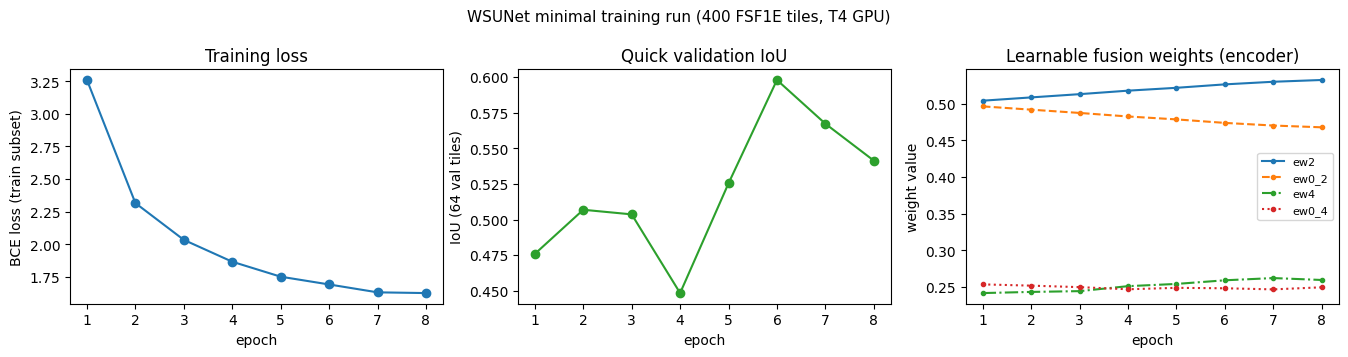

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
ep = np.arange(1, EPOCHS + 1)
axes[0].plot(ep, history["loss"], "o-")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss (train subset)")
axes[0].set_title("Training loss")
axes[1].plot(ep, history["iou64"], "o-", color="tab:green")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("IoU (64 val tiles)")
axes[1].set_title("Quick validation IoU")
for key, ls in [("ew2", "-"), ("ew0_2", "--"), ("ew4", "-."), ("ew0_4", ":")]:
    axes[2].plot(ep, [w[key] for w in history["weights"]], ls, marker=".", label=key)
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("weight value")
axes[2].set_title("Learnable fusion weights (encoder)")
axes[2].legend(fontsize=8)
fig.suptitle("WSUNet minimal training run (400 FSF1E tiles, T4 GPU)", fontsize=11)
fig.tight_layout()
plt.savefig("/content/wsff_training_curves.png", dpi=110, bbox_inches="tight")
plt.show()

## 9. Evaluate on the full validation split (328 tiles)

Metrics computed on **all 328 validation tiles** at threshold 0.5:
**IoU** and **Dice** per image (empty-ground-truth tiles count 1.0 only when the
prediction is also empty), plus **dataset-level pixel precision/recall/F1**.
The paper's exact metric convention is unknown (full text unavailable), so these
standard definitions are documented here rather than claimed as the paper's.

**（日本語）** 全 328 枚の検証タイルで IoU・Dice（画像ごと）と、データセット全体の
pixel precision/recall/F1 を閾値 0.5 で計算します。論文の正確な評価規約は不明のため、
ここでは標準的な定義を明示して使用します。

In [ ]:
import pandas as pd

model.eval()
rows = []
TP = FP = FN = 0
with torch.no_grad():
    for names_b, (x, y) in zip([val_names[i:i + 8] for i in range(0, len(val_ds), 8)], val_dl):
        pred = (torch.sigmoid(model(x.to(DEVICE))) > 0.5).cpu()
        for j, name in enumerate(names_b):
            p, g = pred[j], y[j]
            inter = float((p * g).sum())
            union = float(((p + g) >= 1).sum())
            gt_sum, pr_sum = float(g.sum()), float(p.sum())
            if gt_sum == 0 and pr_sum == 0:
                iou = dice = 1.0
            elif gt_sum == 0 or pr_sum == 0:
                iou = dice = 0.0
            else:
                iou = inter / union
                dice = 2 * inter / (gt_sum + pr_sum)
            TP += int(((p == 1) & (g == 1)).sum())
            FP += int(((p == 1) & (g == 0)).sum())
            FN += int(((p == 0) & (g == 1)).sum())
            rows.append({"tile": name, "IoU": iou, "Dice": dice,
                         "gt_panicle_px": int(gt_sum)})
df = pd.DataFrame(rows)
precision = TP / (TP + FP) if TP + FP else float("nan")
recall = TP / (TP + FN) if TP + FN else float("nan")
f1 = 2 * precision * recall / (precision + recall) if precision + recall else float("nan")
summary = pd.DataFrame({
    "metric": ["mean IoU", "mean Dice", "pixel precision", "pixel recall", "pixel F1"],
    "value": [df["IoU"].mean(), df["Dice"].mean(), precision, recall, f1],
})
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
df.to_csv("/content/wsff_val_tile_metrics.csv", index=False)
print(f"\nper-tile metrics for {len(df)} validation tiles -> /content/wsff_val_tile_metrics.csv")

         metric  value
       mean IoU 0.5602
      mean Dice 0.6947
pixel precision 0.7543
   pixel recall 0.7535
       pixel F1 0.7539

per-tile metrics for 328 validation tiles -> /content/wsff_val_tile_metrics.csv


## 10. Predictions vs reference annotations

Qualitative check on held-out validation tiles: original image, reference
annotation, and the model's binarized prediction, side by side. Predictions come
from the 400-tile training run — with such a small training budget, imperfect
boundaries are expected.

**（日本語）** 検証タイルについて、原画像・参照アノテーション・予測マスクを並べて表示します。
学習は 400 枚と少ないため、境界は完全ではありません。

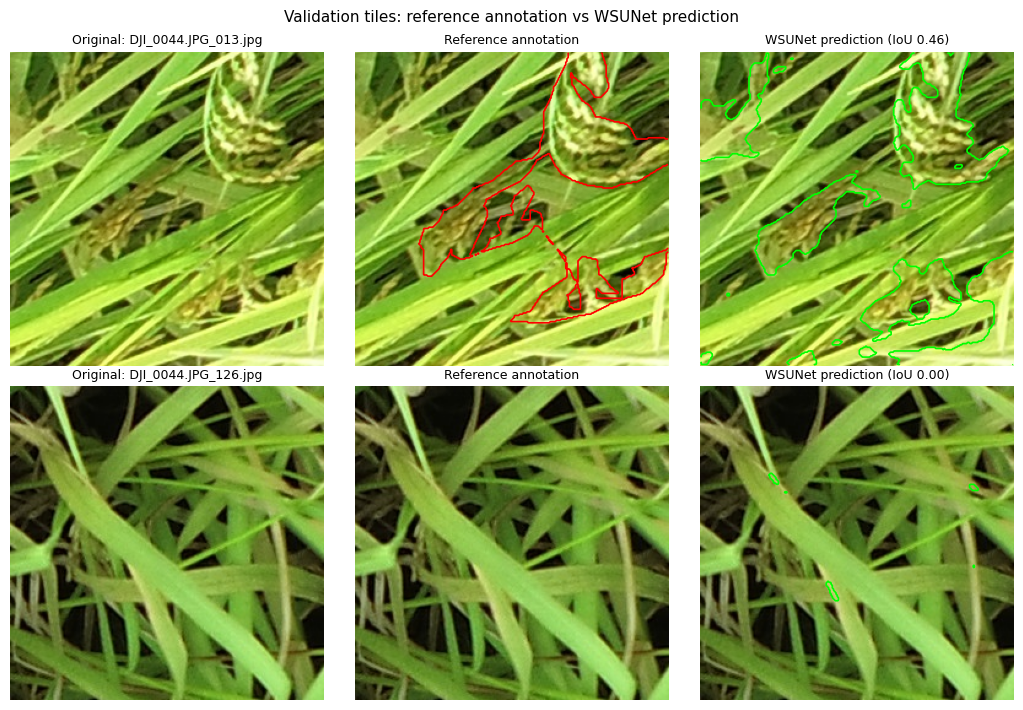

In [ ]:
show_idx = [0, 5]  # first two validation tiles (deterministic)
fig, axes = plt.subplots(len(show_idx), 3, figsize=(10.5, 3.6 * len(show_idx)))
model.eval()
with torch.no_grad():
    for r, i in enumerate(show_idx):
        x, y = val_ds[i]
        pred = (torch.sigmoid(model(x.unsqueeze(0).to(DEVICE))) > 0.5).cpu()[0, 0].numpy()
        img = x.permute(1, 2, 0).numpy()
        g = y[0].numpy()
        axes[r, 0].imshow(img); axes[r, 0].set_title(f"Original: {val_names[i]}", fontsize=9)
        axes[r, 1].imshow(img); axes[r, 1].contour(g, levels=[0.5], colors="red", linewidths=1.2)
        axes[r, 1].set_title("Reference annotation", fontsize=9)
        axes[r, 2].imshow(img); axes[r, 2].contour(pred, levels=[0.5], colors="lime", linewidths=1.2)
        axes[r, 2].set_title(f"WSUNet prediction (IoU {df.IoU.iloc[i]:.2f})", fontsize=9)
        for c in range(3):
            axes[r, c].axis("off")
fig.suptitle("Validation tiles: reference annotation vs WSUNet prediction", fontsize=11)
fig.tight_layout()
plt.savefig("/content/wsff_predictions.png", dpi=110, bbox_inches="tight")
plt.show()

## 11. Interpretation, limitations, and references

**What was demonstrated (this run, T4 GPU):** the author's WSUNet at the pinned
commit was trained on 400 FSF1E tiles and evaluated on all 328 validation tiles
(see the table above and `wsff_val_tile_metrics.csv`); the learnable fusion
weights moved from their hand-set initial values during training.

**What this is NOT:** it is not a reproduction of the paper's reported metrics —
the training subset is 400/1418 tiles, the number of epochs is small, and the
loss/optimizer/epoch choices are AI defaults because the paper's protocol is
unavailable (full text inaccessible). The paper also compares WSUNet against
UNet/NestedUNet/WS1UNet/WS2UNet baselines and reports results on FSF2L; those
comparisons are out of scope for this minimal experience.

**（日本語）** 本ノートブックは、著者コードの WSUNet を FSF1E の 400 タイルで学習し、
検証 328 タイルで評価する最小デモです。著者の学習プロトコルが不明のため、数値は論文の
ベンチマーク再現ではありません。ベースライン比較や FSF2L は対象外です。

**References**
- Xiao, L., Pan, Z., Du, X., Chen, W., Qu, W., Bai, Y., Xu, T. (2023).
  Weighted skip-connection feature fusion: A method for augmenting UAV oriented
  rice panicle image segmentation. *Computers and Electronics in Agriculture*, 207, 107754.
  https://doi.org/10.1016/j.compag.2023.107754
- Code & data: https://github.com/rooooolin/wsff @ `0d3bc2487bf01339ee231dbd15368762d6b612d6`
  (no license file present in the repository at that commit; used here for
  research demonstration with attribution — reuse terms should be confirmed
  before any redistribution).